In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from tensorflow import keras
from tensorflow.keras import layers

In [11]:
train = pd.read_csv("FNN and CNN/Fashion MNIST/fashion-mnist_train.csv")
test = pd.read_csv("FNN and CNN/Fashion MNIST/fashion-mnist_test.csv")

x_train = train.iloc[:, 1:].values / 255.0
y_train = train.iloc[:, 0].values

x_test = test.iloc[:, 1:].values / 255.0
y_test = test.iloc[:, 0].values

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (60000, 784)
Testing data: (10000, 784)


In [12]:
model = keras.Sequential([
    keras.Input(shape=(784,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
model.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.01),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [14]:
history = model.fit(
    x_train, y_train,
    epochs=11,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/11
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.6997 - loss: 0.9579 - val_accuracy: 0.7713 - val_loss: 0.6883
Epoch 2/11
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 859us/step - accuracy: 0.7938 - loss: 0.6187 - val_accuracy: 0.8078 - val_loss: 0.5793
Epoch 3/11
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 869us/step - accuracy: 0.8163 - loss: 0.5506 - val_accuracy: 0.8188 - val_loss: 0.5351
Epoch 4/11
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 932us/step - accuracy: 0.8245 - loss: 0.5142 - val_accuracy: 0.8303 - val_loss: 0.5111
Epoch 5/11
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 857us/step - accuracy: 0.8331 - loss: 0.4908 - val_accuracy: 0.8302 - val_loss: 0.4970
Epoch 6/11
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 853us/step - accuracy: 0.8371 - loss: 0.4745 - val_accuracy: 0.8380 - val_loss: 0.4801
Epoch 7/11
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 852us/step - accuracy: 0.8419 - loss: 0.4609 - val_accuracy: 0.8421 - val_loss: 0.4662
Epoch 8/11
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8439 - loss: 0.4497 - val_

In [15]:
loss, accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 461us/step - accuracy: 0.8545 - loss: 0.4344
Test Loss: 0.4344291388988495
Test Accuracy: 0.8544999957084656


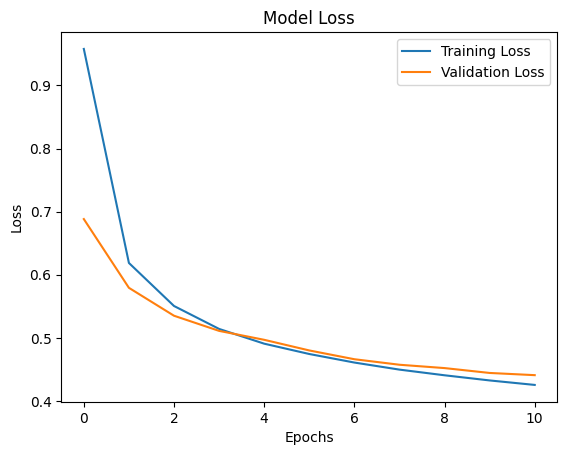

In [16]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

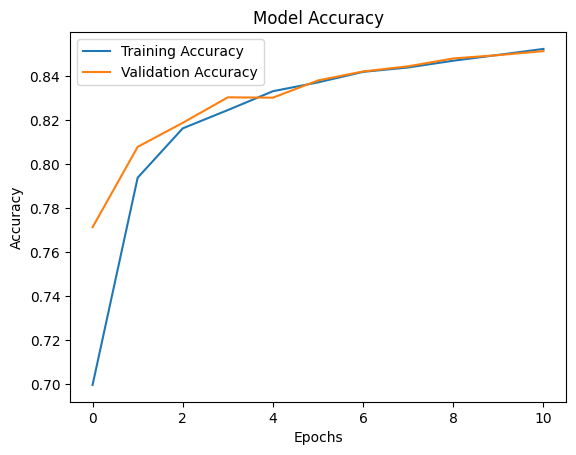

In [17]:
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [18]:
class_names = [
    "T-shirt", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

prediction = model.predict(x_test[:1])

print("Predicted:", class_names[np.argmax(prediction[0])])
print("Actual:", class_names[y_test[0]])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
Predicted: T-shirt
Actual: T-shirt
